In [1]:
import pandas as pd
import glob
import os
import re
from tqdm import tqdm

def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Only add *_out columns if they exist in the dataframe
    for c in cn_cols:
        out_col = c + '_out'
        if out_col in result.columns:
            result.loc[:, c] = result[c] + result[out_col]
    
    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))
    
    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


# Initialize empty dataframe
df = pd.DataFrame()
folder = 'modeling_C8_10h'
folder = 'modeling_C16_10h'
folder = 'modeling_C16_10h_noback'
folder = 'modeling_C16_10h_corrected_151025_flow'
folder = 'modeling_C16_10h_corrected_151025V2'
# Get all distribution files
files = glob.glob(f'files/{folder}/ts_temperature_*_pressure_*_N_*_diffusion_*_stream_*_particleSize_*_cat_conc_*.pkl')


In [5]:
failed_runs = []
if os.path.exists(f'files/{folder}/all_distributions.pkl'):
    df = pd.read_pickle(f'files/{folder}/all_distributions.pkl')

else:
    for file in tqdm(files):
        # Extract parameters from filename
        params = file.split('_')
        temperature = float(params[params.index('temperature')+1])
        pressure = float(params[params.index('pressure')+1])
        N = int(params[params.index('N')+1])
        diffusion = params[params.index('diffusion')+1] == 'True'
        stream = params[params.index('stream')+1] == 'True'
        ps = int(float(params[params.index('particleSize')+1]))
        cat_conc = float(params[params.index('conc')+1][:-4])

        # Read distribution file
        # distr = pd.read_pickle(file)
        distr = time_distribution(pd.read_pickle(file).reset_index(names=['time']).iloc[::100])
        # Add parameters as columns
        distr['temperature'] = temperature
        distr['pressure'] = pressure
        distr['N'] = N
        distr['diffusion'] = diffusion
        distr['is_stream'] = stream
        distr['particle_size'] = ps
        distr['cat_conc'] = cat_conc
        
        # Append to main dataframe
        df = pd.concat([df, distr], ignore_index=True)


    df = df.drop_duplicates()
    dft = df.groupby(['temperature', 'pressure', 'N', 'is_stream', 'diffusion', 'particle_size', 'cat_conc']).count().reset_index()
    df=df.sort_values(['pressure', 'temperature', 'n'])

    df.to_pickle(f'files/{folder}/all_distributions.pkl')

df.info()

100%|██████████| 10328/10328 [01:41<00:00, 101.32it/s]


<class 'pandas.core.frame.DataFrame'>
Index: 722960 entries, 0 to 722889
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   time           722960 non-null  float64
 1   n              722960 non-null  int64  
 2   probability    650664 non-null  float64
 3   temperature    722960 non-null  float64
 4   pressure       722960 non-null  float64
 5   N              722960 non-null  int64  
 6   diffusion      722960 non-null  bool   
 7   is_stream      722960 non-null  bool   
 8   particle_size  722960 non-null  int64  
 9   cat_conc       722960 non-null  float64
dtypes: bool(2), float64(5), int64(3)
memory usage: 51.0 MB


In [6]:
dft = df[df.n != 2].copy()

dft = dft[dft.time.between(3595, 3605)]

# expectation terms
dft['exp_n']  = dft['probability'] * dft['n']
dft['exp_n2'] = dft['probability'] * (dft['n'] ** 2)

# group by and aggregate
df_grouped = (dft.groupby(
        ['temperature', 'pressure', 'is_stream', 'diffusion', 'particle_size', 'cat_conc'],
        as_index=False
    )
    .agg(expected_n=('exp_n','sum'),
         expected_n2=('exp_n2','sum'))
)

# variance and standard deviation
df_grouped['variance_n'] = df_grouped['expected_n2'] - df_grouped['expected_n']**2
df_grouped['std_n'] = df_grouped['variance_n']**0.5
df_grouped['coefficient_variance'] = df_grouped.std_n/df_grouped.expected_n
df_grouped.coefficient_variance.describe(), df_grouped.expected_n.describe()

(count    10328.000000
 mean         0.241172
 std          0.124770
 min          0.000464
 25%          0.165059
 50%          0.242586
 75%          0.326417
 max          0.528374
 Name: coefficient_variance, dtype: float64,
 count    10328.000000
 mean         7.657972
 std          3.434218
 min          4.000002
 25%          4.940190
 50%          6.257135
 75%         10.316005
 max         15.274864
 Name: expected_n, dtype: float64)

In [7]:
df.to_pickle(f'files/processed/all_distributions_151025.pkl')
df_grouped.to_pickle(f'files/processed/all_distributions_summary_151025.pkl')

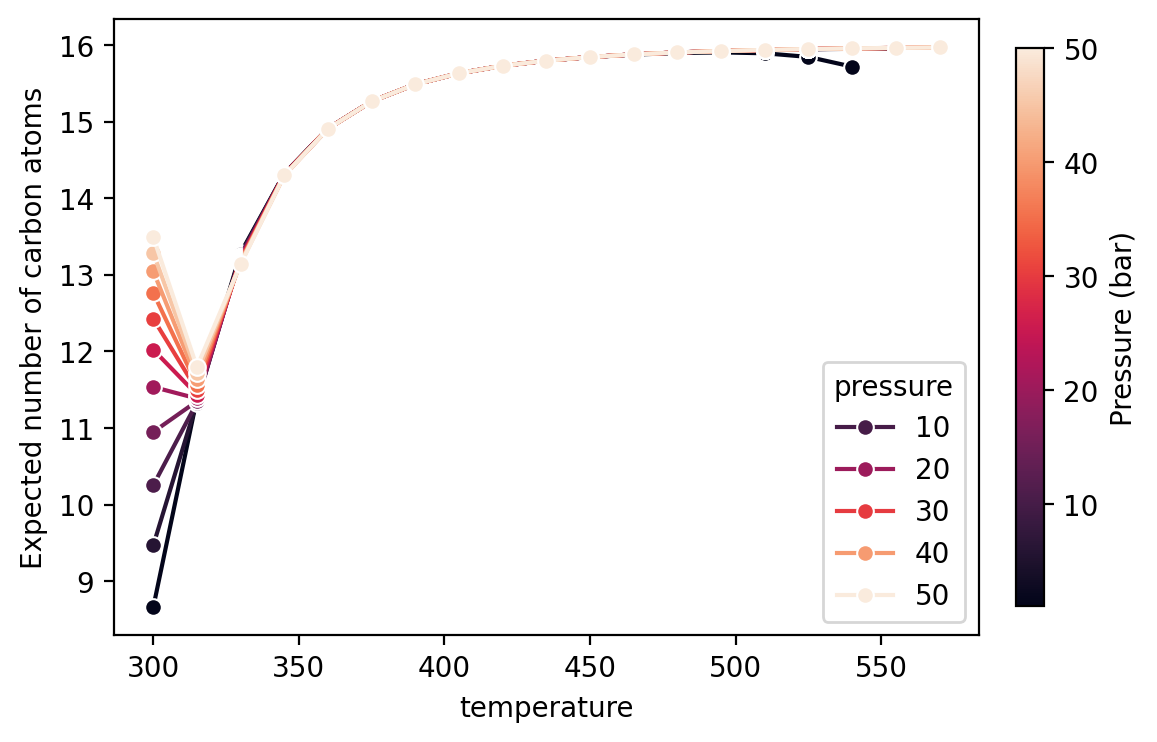

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 1, figsize=(6, 4), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and is_stream and particle_size > 1e14')

cmap = "rocket"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

sns.lineplot(
    data=dft,
    x='temperature', y='expected_n', hue='pressure',
    marker='o', ax=axs,
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)

axs.set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

# fig.savefig("files/plots/distribution_no_back_SI.pdf", bbox_inches="tight")
# fig.savefig("files/plots/distribution_no_back_SI.svg", bbox_inches="tight")

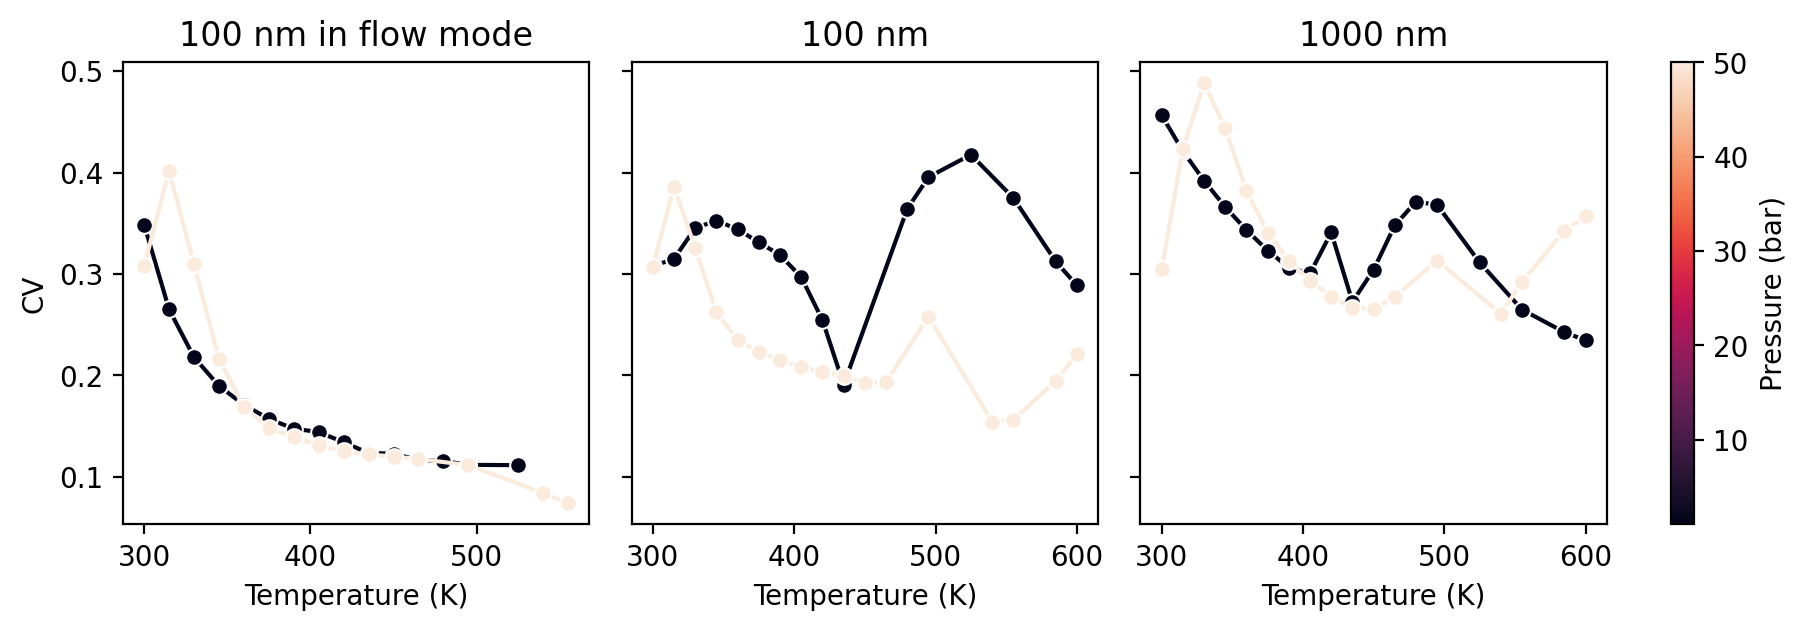

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 3, figsize=(10, 3), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and not is_stream')


norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, ax) in enumerate([
    (300, True, axs[1]),
    (1000, False, axs[2])
]):
    data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"}')
    sns.lineplot(
        data=data,
        x='temperature', y='coefficient_variance', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )
data=df_grouped.query('is_stream and is_stream and cat_conc == 0.01 and particle_size == 300')
data = data.sort_values(by=['pressure', 'temperature'])
sns.lineplot(
    data=data,
    x='temperature', y='coefficient_variance', hue='pressure',
    marker='o', ax=axs[0],
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)


for title, ax in zip(('100 nm in flow mode', '100 nm', '1000 nm', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('CV')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_CV.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.svg", bbox_inches="tight")

# Kinetic analysis

In [1]:
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorptionSimplified, ReactorSimulationChemisorption
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed, EnergyBarriers
import numpy as np
import joblib
from tqdm import tqdm
import pandas as pd

In [ ]:

c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

N = 8
temperature = 300  # Kelvin
pressure = 2  # bar
steps = 1e4
time = 10
diffusion = False  # Set to False to disable diffusion

df_rates = []
with tqdm(total=101*6) as pbar:
    for temperature in np.linspace(300, 600, 101):
        for pressure in np.linspace(1, 50, 6):

            energy_barriers = EnergyBarriersSimplifyed(
                temperature=temperature,
                pressure=pressure
            )

            reactor = ReactorSimulationChemisorptionSimplified(
                N=N,
                T=temperature,
                pressure=pressure,
                L=1000,
                time_hours=time,
                n_steps=int(steps),
                diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
                ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
                energy_model=energy_barriers,
                initial_concs={'CatC2(C2)': 1e-2, 'C2': 1, 'C2_out': 1},
                include_diffusion=diffusion
            )

            reactor.solver = reactor._build_solver()
            k_ins, k_deins = reactor._reactions[2][1:]
            k_elim, k_deelim = reactor._reactions[-1][1:]
            df_rates.append([k_ins, k_deins, k_elim, k_deelim, pressure, temperature])
            pbar.update(1)

df_rates = pd.DataFrame(df_rates, columns = ['k_ins', 'k_deins', 'k_elim', 'k_deelim', 
                                             'pressure', 'temperature'])
df_rates.to_pickle('files/rates.pkl')

 51%|█████     | 307/606 [00:28<00:28, 10.53it/s]

In [2]:
distr = pd.read_pickle('files/distr.pkl')
df_rates = pd.read_pickle('files/rates.pkl')
# distr = distr.query('not diffusion and particle_size==1000')
distr = pd.read_pickle(f'files/processed/all_distributions_summary_071025.pkl')
distr = distr.query('not diffusion and particle_size==1000')

In [3]:
distr['pressure'] = distr['pressure'].round(1)
distr['temperature'] = distr['temperature'].round(1)
df_rates['pressure'] = df_rates['pressure'].round(1)
df_rates['temperature'] = df_rates['temperature'].round(1)

merged = pd.merge(
    distr,
    df_rates,
    on=['pressure', 'temperature'],
    suffixes=('_distr', '_rates')
)
merged = merged.drop(columns=['is_stream', 'diffusion', 'cat_conc', 'expected_n2', 'variance_n', 'std_n', 'particle_size'])
merged['K growth'] = merged.k_ins/merged.k_deins
merged['K elimination'] = merged.k_elim/merged.k_deelim

merged = merged.rename(columns={'k_ins': 'insertion rate', 'k_deins': 'de-insertion rate',
                            'k_elim': 'elimination rate', 'k_deelim': 'de-elimination rate'})
merged.head()

,temperature,pressure,expected_n,coefficient_variance,insertion rate,de-insertion rate,elimination rate,de-elimination rate,K growth,K elimination
0,300.0,1.0,5.206493,0.387731,0.068697,1.743626e-11,2.143486,394.807435,3.939873e+09,0.005429
1,300.0,1.0,8.339491,0.459136,0.068697,1.743626e-11,2.143486,394.807435,3.939873e+09,0.005429
2,300.0,1.0,8.744805,0.445623,0.068697,1.743626e-11,2.143486,394.807435,3.939873e+09,0.005429
3,300.0,10.8,8.988636,0.509605,0.068697,1.614270e-12,0.198446,36.551733,4.255588e+10,0.005429
4,300.0,10.8,10.374787,0.461479,0.068697,1.614270e-12,0.198446,36.551733,4.255588e+10,0.005429


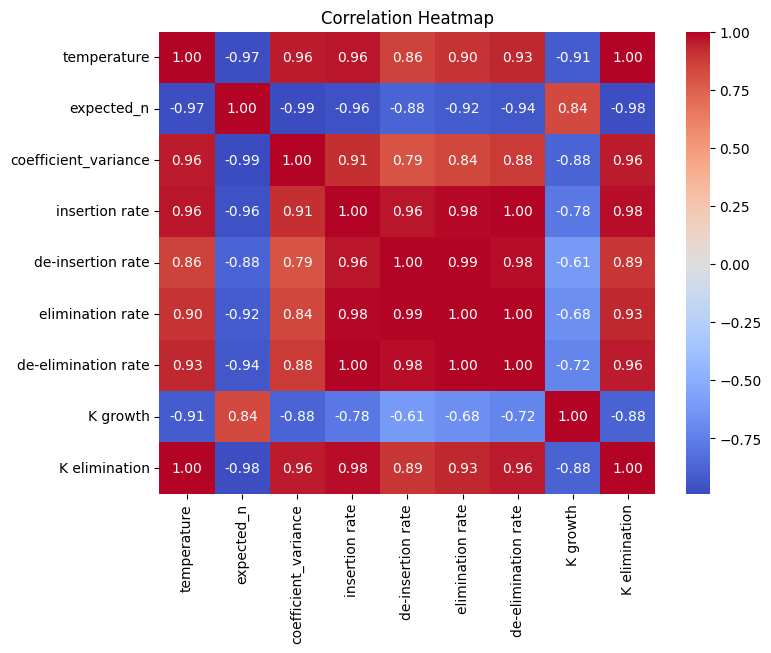

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(merged.query('pressure==50 and 520 < temperature < 1530').drop(columns=['pressure']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

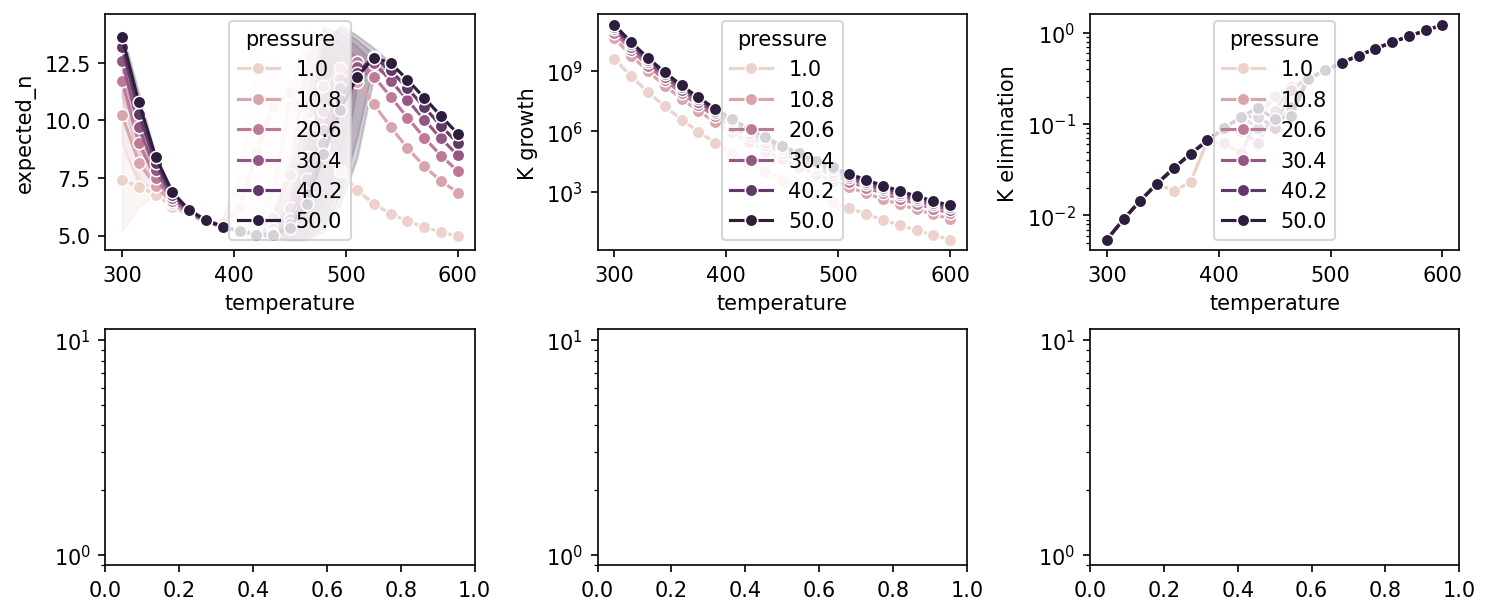

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(12, 5),dpi=150)
sns.lineplot(merged, x='temperature', y='expected_n', hue='pressure', marker='o', ax=axs[0, 0])
sns.lineplot(merged, x='temperature', y='K growth', hue='pressure', marker='o', ax=axs[0, 1])
sns.lineplot(merged, x='temperature', y='K elimination', hue='pressure', marker='o', ax=axs[0, 2])

# sns.lineplot(merged, x='temperature', y='insertion rate', hue='pressure', marker='o', ax=axs[1, 0])
# sns.lineplot(merged, x='temperature', y='k elimination', hue='pressure', marker='o', ax=axs[1, 1])
# sns.lineplot(merged, x='temperature', y='k deelim', hue='pressure', marker='o', ax=axs[1, 2])


axs[0, 1].set_yscale('log')
axs[0, 2].set_yscale('log')
axs[1, 0].set_yscale('log')
axs[1, 1].set_yscale('log')
axs[1, 2].set_yscale('log')
for ax in axs.flatten():
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width*0.9, box.height*0.9])

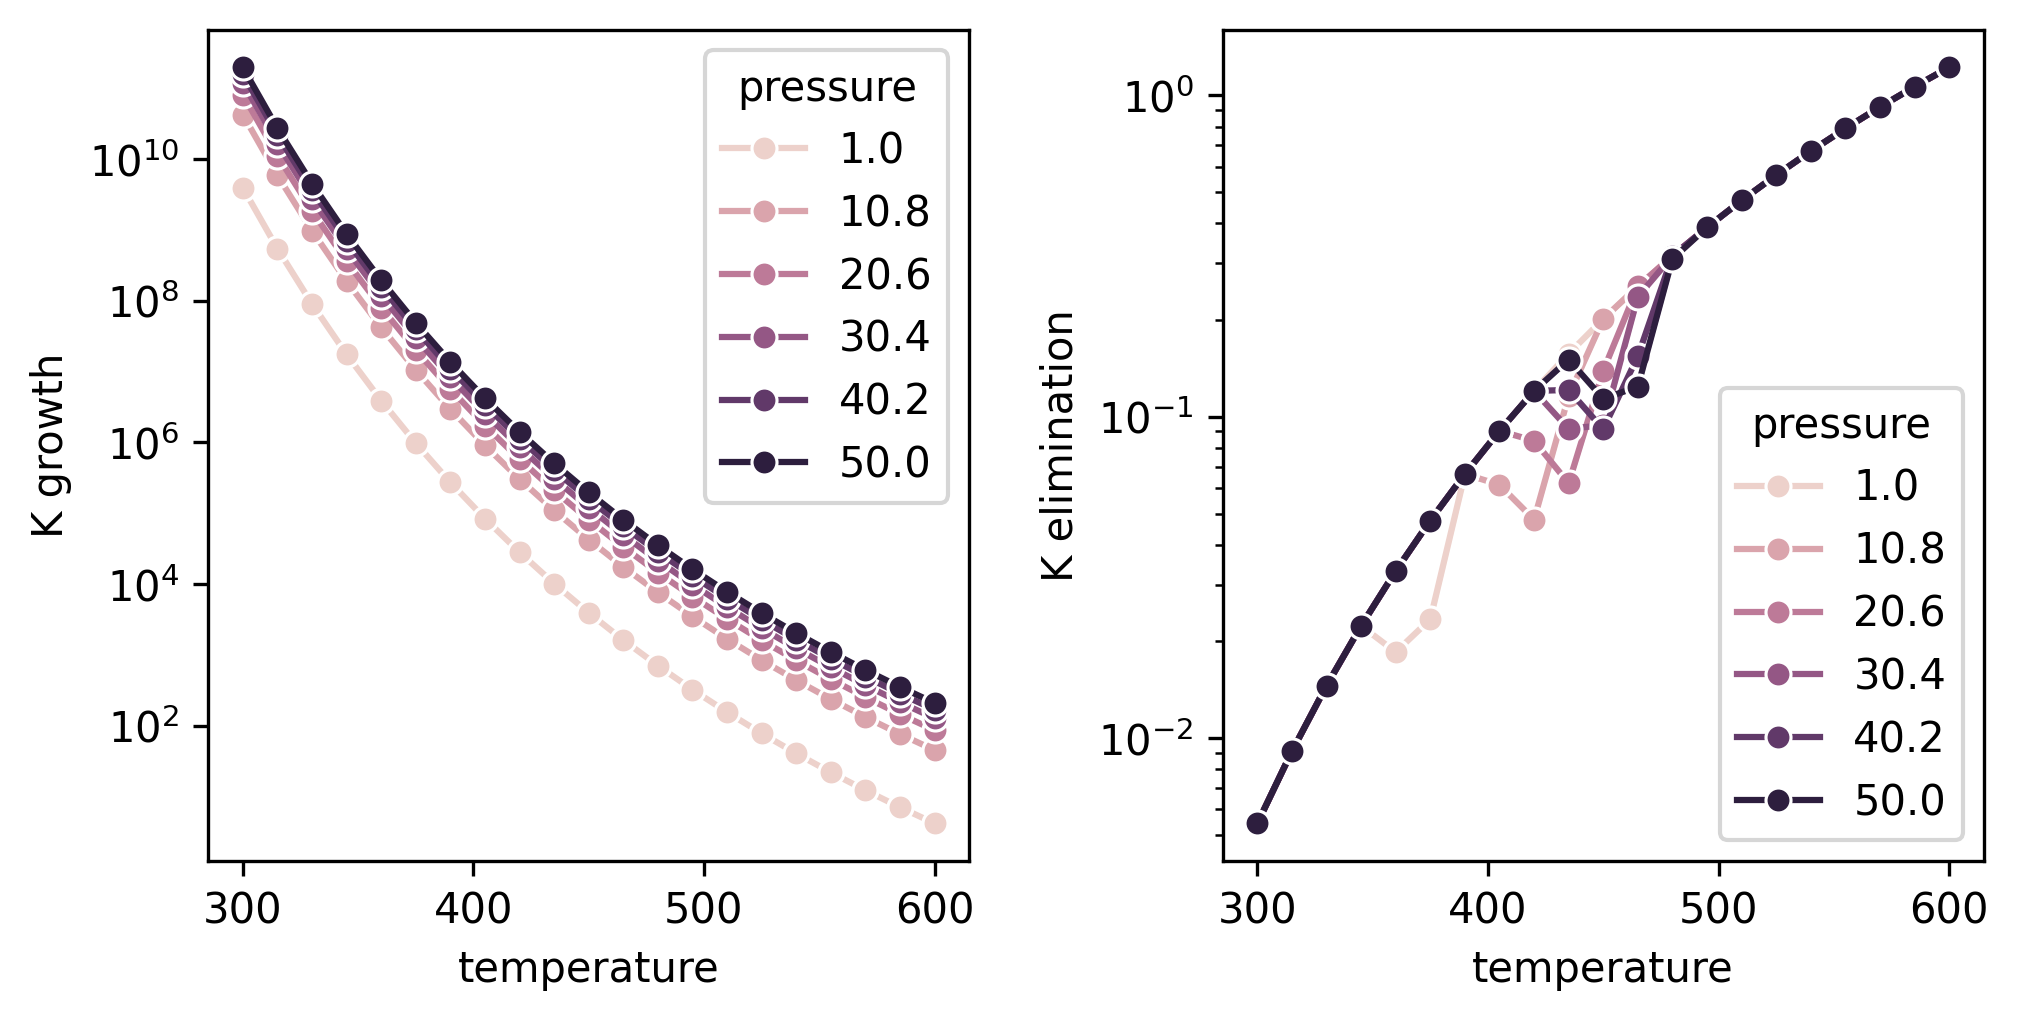

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), dpi=300)
sns.lineplot(merged, x='temperature', y='K growth', hue='pressure', marker='o', ax=axs[0])
sns.lineplot(merged, x='temperature', y='K elimination', hue='pressure', marker='o', ax=axs[1])

axs[0].set_yscale('log')
axs[1].set_yscale('log')
for ax in axs.flatten():
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width*0.9, box.height*0.9])

fig.savefig("files/plots/rates.pdf", bbox_inches="tight")